# Cycle 3 - Comparaison de modèles

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
from sklearn.pipeline import Pipeline
from agritech_feature_engineering import AgritechFeatureEngineering
from sklearn.model_selection import cross_validate, TimeSeriesSplit
import mlflow
import notebooks.utils as utils
from datetime import datetime as dt
import numpy as np

In [3]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")

In [4]:
dataset = pd.read_csv('../data/rafined/dataset.csv', sep=',', na_values=[''], quotechar='"')

In [5]:
dataset.drop(columns=['Area ISO Code', 'Area ISO Alpha-2 Code', 'Area ISO Alpha-3 Code'], inplace=True)

In [6]:
X_train, X_test, y_train, y_test = utils.test_train_time_split(dataset)

Année de césure calculée : 2009
Proportion réelle train : 78.73% (20349 lignes)
Proportion réelle test  : 21.27% (5499 lignes)


In [7]:
X_train = X_train.sort_values('Year')
y_train = y_train.loc[X_train.index]

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor

numeric_features = [
    'avg_temp',
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'pesticides_kg_ha',
    'aridity',
    'avg_temp_square',
    'missing_pesticide_value',
    'missing_rain_value',
    'missing_temp_value'
]

numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('area_encoding', TargetEncoder(target_type='continuous', random_state=42), ['Area']),
        ('item_encoding', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Item']),
        ('num_pipeline', numeric_transformer, numeric_features),
    ],
    remainder='drop'
)

In [9]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge

models = {
    'ridge': Ridge(random_state=42),
    'k_neighbors': KNeighborsRegressor(),
    'random_forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'hist_gradient_boosting': HistGradientBoostingRegressor(random_state=42),
    'gradient_boosting': GradientBoostingRegressor(random_state=42),
}

In [10]:
mlflow.set_experiment("Agriculture_optimization")
mlflow.end_run()
mlflow.set_system_metrics_sampling_interval(1)

2026/11/11 10:09:40 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/11 10:09:40 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/11 10:09:40 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/11 10:09:40 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/11 10:09:41 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/11 10:09:41 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


--- ridge ---
Validation : R2 = 0.6522 | MAE = 25401 | RMSE = 43141
Train      : R2 = 0.6834 | MAE = 22369 | RMSE = 38454
Temps d'entraînement moyen par pli : 0.02 s
🏃 View run Cycle 3 - ridge at: http://127.0.0.1:5000/#/experiments/1/runs/7c657a5097034a96acd398c8cccbb2f0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/11/11 10:09:41 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/11 10:09:41 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/11 10:09:41 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/11 10:09:41 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


--- k_neighbors ---
Validation : R2 = 0.8462 | MAE = 14640 | RMSE = 28513
Train      : R2 = 0.9238 | MAE = 8872 | RMSE = 18364
Temps d'entraînement moyen par pli : 0.02 s
🏃 View run Cycle 3 - k_neighbors at: http://127.0.0.1:5000/#/experiments/1/runs/9ab00200bc1d4aae92abb80823e7bcbd
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/11/11 10:09:45 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/11 10:09:45 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/11 10:09:45 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/11 10:09:45 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


--- random_forest ---
Validation : R2 = 0.8729 | MAE = 13400 | RMSE = 25951
Train      : R2 = 0.9692 | MAE = 5442 | RMSE = 11882
Temps d'entraînement moyen par pli : 0.57 s
🏃 View run Cycle 3 - random_forest at: http://127.0.0.1:5000/#/experiments/1/runs/70404dd957ff4dbf887d655a6ce642cb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/11/11 10:09:53 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/11 10:09:53 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/11 10:09:53 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/11 10:09:53 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


--- hist_gradient_boosting ---
Validation : R2 = 0.8011 | MAE = 18633 | RMSE = 32605
Train      : R2 = 0.8690 | MAE = 14012 | RMSE = 24722
Temps d'entraînement moyen par pli : 1.62 s
🏃 View run Cycle 3 - hist_gradient_boosting at: http://127.0.0.1:5000/#/experiments/1/runs/918c413ab6704c03977551030dda70fa
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/11/11 10:09:59 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/11 10:09:59 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


--- gradient_boosting ---
Validation : R2 = 0.7169 | MAE = 22992 | RMSE = 38919
Train      : R2 = 0.7664 | MAE = 19468 | RMSE = 33032
Temps d'entraînement moyen par pli : 1.04 s
🏃 View run Cycle 3 - gradient_boosting at: http://127.0.0.1:5000/#/experiments/1/runs/38d9816b6d9943999ef9dd634b1619c0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


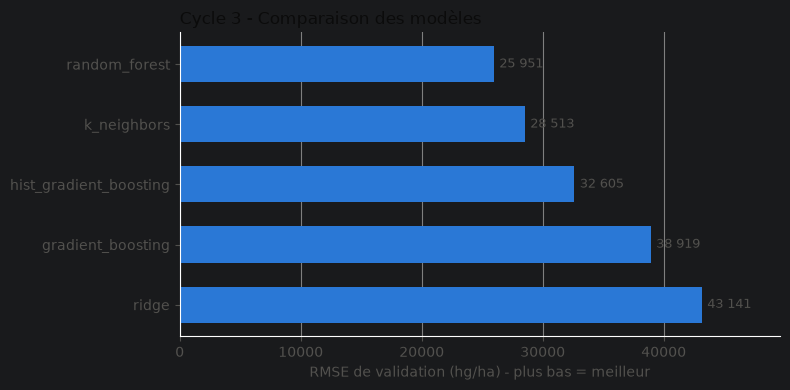

🏃 View run Cycle 3 - Comparaison des modèles at: http://127.0.0.1:5000/#/experiments/1/runs/0323651be99d45ec987d8c733578503a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,model,r2,mae,rmse,train_r2,train_mae,train_rmse,fit_time_mean,score_time_mean,r2_gap_train_val
0,random_forest,0.872883,13399.668255,25951.179634,0.969214,5442.009479,11881.998839,0.571024,0.027820,0.096331
1,k_neighbors,0.846175,14639.830590,28512.733460,0.923849,8871.642165,18364.394660,0.020460,0.046326,0.077674
2,hist_gradient_boosting,0.801129,18632.565939,32605.491820,0.869035,14011.861364,24722.355329,1.623935,0.018905,0.067907
3,gradient_boosting,0.716913,22992.457015,38918.906163,0.766445,19468.255402,33032.105624,1.040392,0.008884,0.049532
4,ridge,0.652207,25401.267168,43140.745639,0.683407,22369.084319,38453.938571,0.023238,0.005838,0.031200


In [11]:
import matplotlib.pyplot as plt

scoring = {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}

# Description de chaque modèle, affichée dans MLflow
descriptions = {
    'ridge': "Ridge : régression linéaire régularisée (L2), référence linéaire.",
    'k_neighbors': "K plus proches voisins : prédit à partir des situations les plus similaires.",
    'random_forest': "Random Forest : moyenne de nombreux arbres de décision indépendants (bagging).",
    'hist_gradient_boosting': "Gradient boosting par histogrammes : arbres construits successivement pour corriger les erreurs des précédents.",
    'gradient_boosting': "Gradient boosting classique : version historique, plus lente, du boosting d'arbres.",
}

# Paramètres communs à tous les modèles (conditions de comparaison identiques)
common_params = {
    'split': 'temporel',
    'split_year': int(X_test['Year'].min()),
    'cv': 'TimeSeriesSplit 5 plis',
    'target_transform': 'log1p',
    'features': 'Area, Item, avg_temp, rain, pesticides, aridity, avg_temp_square, missing_*',
}

results = []

# Run parent : regroupe tous les modèles comparés dans ce cycle
with mlflow.start_run(run_name="Cycle 3 - Comparaison des modèles"):

    mlflow.set_tags({
        'date': dt.now().strftime("%Y-%m-%d"),
        'cycle': '3_comparaison',
        'mlflow.note.content': (
            "Comparaison de plusieurs familles de modèles (linéaire, voisins, bagging, boosting) "
            "avec les paramètres par défaut, dans les mêmes conditions : même pipeline, "
            "même cible log1p, même validation croisée temporelle. "
            "Chaque modèle est un run enfant ; le meilleur (RMSE la plus faible) est indiqué dans le tag best_model."
        ),
    })

    mlflow.log_params({**common_params, 'models': ', '.join(models)})

    for model_name, model in models.items():

        pipeline = Pipeline([
            ('features', AgritechFeatureEngineering()),
            ('preprocessor', preprocessor),
            ('model', model)
        ])

        model_log = TransformedTargetRegressor(
            regressor=pipeline,
            func=np.log1p,
            inverse_func=np.expm1,
        )

        # Run enfant : un par modèle, rattaché au run parent
        with mlflow.start_run(run_name=f"Cycle 3 - {model_name}", nested=True, log_system_metrics=True):

            mlflow.set_tags({
                'date': dt.now().strftime("%Y-%m-%d"),
                'cycle': '3_comparaison',
                'model_type': model_name,
                'mlflow.note.content': descriptions.get(model_name, model_name),
            })

            mlflow.log_params({**common_params, 'model': type(model).__name__})
            # hyperparamètres du modèle (valeurs par défaut à ce stade), préfixés pour les distinguer
            mlflow.log_params({f'model__{k}': v for k, v in model.get_params().items()})

            cv_results = cross_validate(
                model_log,
                X_train,
                y_train,
                cv=TimeSeriesSplit(5),
                scoring=scoring,
                return_train_score=True,
                error_score='raise'
            )

            metrics = {
                'r2': cv_results['test_r2'].mean(),
                'mae': -cv_results['test_mae'].mean(),
                'rmse': -cv_results['test_rmse'].mean(),
                'train_r2': cv_results['train_r2'].mean(),
                'train_mae': -cv_results['train_mae'].mean(),
                'train_rmse': -cv_results['train_rmse'].mean(),
                'fit_time_mean': cv_results['fit_time'].mean(),
                'score_time_mean': cv_results['score_time'].mean(),
            }
            # écart train / validation : plus il est grand, plus le modèle surapprend
            metrics['r2_gap_train_val'] = metrics['train_r2'] - metrics['r2']
            mlflow.log_metrics(metrics)

            # scores de chaque pli (step = numéro du pli) pour visualiser la stabilité dans MLflow
            for fold in range(len(cv_results['test_r2'])):
                mlflow.log_metrics({
                    'fold_r2': cv_results['test_r2'][fold],
                    'fold_mae': -cv_results['test_mae'][fold],
                    'fold_rmse': -cv_results['test_rmse'][fold],
                }, step=fold)

            results.append({'model': model_name, **metrics})

            print(f"--- {model_name} ---")
            print(f"Validation : R2 = {metrics['r2']:.4f} | MAE = {metrics['mae']:.0f} | RMSE = {metrics['rmse']:.0f}")
            print(f"Train      : R2 = {metrics['train_r2']:.4f} | MAE = {metrics['train_mae']:.0f} | RMSE = {metrics['train_rmse']:.0f}")
            print(f"Temps d'entraînement moyen par pli : {metrics['fit_time_mean']:.2f} s")

    # Tableau de comparaison, trié du meilleur au moins bon (RMSE croissante)
    comparison = pd.DataFrame(results).sort_values('rmse').reset_index(drop=True)
    best = comparison.iloc[0]

    mlflow.set_tag('best_model', best['model'])
    mlflow.log_metrics({
        'best_r2': best['r2'],
        'best_mae': best['mae'],
        'best_rmse': best['rmse'],
    })
    mlflow.log_table(comparison, artifact_file='comparaison_modeles.json')

    # Graphique : RMSE de validation par modèle
    fig, ax = plt.subplots(figsize=(8, 4))
    ordered = comparison.sort_values('rmse', ascending=False)
    bars = ax.barh(ordered['model'], ordered['rmse'], color='#2a78d6', height=0.6)
    ax.bar_label(bars, labels=[f"{v:,.0f}".replace(',', ' ') for v in ordered['rmse']], padding=4, color='#52514e', fontsize=9)
    ax.set_xlabel('RMSE de validation (hg/ha) - plus bas = meilleur', color='#52514e')
    ax.set_title('Cycle 3 - Comparaison des modèles', loc='left', color='#0b0b0b')
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(colors='#52514e')
    ax.grid(axis='x', color='#e5e5e3', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_xlim(0, ordered['rmse'].max() * 1.15)
    fig.tight_layout()
    mlflow.log_figure(fig, 'comparaison_rmse.png')
    plt.show()

comparison

## Conclusion du cycle 3 : comparaison de modèles

**Principe** : cinq modèles de familles différentes sont comparés avec leurs **paramètres par défaut**, dans des conditions identiques : même prétraitement, même cible en log, même validation croisée temporelle (5 plis) et même graine aléatoire (`random_state=42`). Tous les runs sont regroupés sous le run parent « Cycle 3 - Comparaison des modèles » dans MLflow.

**Résultats (validation croisée temporelle, classés par RMSE)** :

| Rang | Modèle | R² | MAE (hg/ha) | RMSE (hg/ha) | R² train | Écart train / validation | Temps d'entraînement par pli |
|---|---|---|---|---|---|---|---|
| 1 | **Random Forest** | **0.873** | **13 400** | **25 951** | 0.969 | 0.096 | 0.57 s |
| 2 | K plus proches voisins | 0.846 | 14 640 | 28 513 | 0.924 | 0.078 | 0.02 s |
| 3 | HistGradientBoosting | 0.801 | 18 633 | 32 605 | 0.869 | 0.068 | 1.62 s |
| 4 | GradientBoosting | 0.717 | 22 992 | 38 919 | 0.766 | 0.050 | 1.04 s |
| 5 | Ridge | 0.652 | 25 401 | 43 141 | 0.683 | 0.031 | 0.02 s |

Rappel de la baseline naïve (médiane pays × culture, évaluée sur le test 2009 à 2013) : R² = 0.836, RMSE = 32 646 hg/ha, MAE = 16 461 hg/ha.

**Interprétation** :
- **Les modèles non linéaires confirment le diagnostic des cycles 1 et 2** : dès qu'un modèle peut apprendre des effets différents selon la culture et le pays, l'erreur chute. La Random Forest divise presque par deux l'erreur moyenne de Ridge (MAE de 13 400 contre 25 401 hg/ha). Ridge obtient logiquement les mêmes scores que la régression linéaire du cycle 2 : la régularisation ne change rien quand le problème vient de la forme du modèle.
- **La Random Forest est le seul modèle à battre nettement la baseline naïve** : environ 19 % d'erreur moyenne en moins (MAE 13 400 contre 16 461) et 21 % de RMSE en moins. Concrètement, elle se trompe en moyenne d'environ 1,3 tonne par hectare, contre 1,6 tonne pour la baseline. Les deux évaluations ne portent pas exactement sur les mêmes années, ce gain sera donc vérifié sur le jeu de test au cycle 5. Les K plus proches voisins font à peine mieux que la baseline, et les deux gradient boostings font moins bien.
- **Les gradient boostings sous-apprennent avec leurs réglages par défaut** : leurs scores sur le train restent bas (R² 0.77 à 0.87), signe que les paramètres par défaut (100 arbres peu profonds) ne suffisent pas pour ces données. Leur classement pourrait changer après optimisation.
- **La Random Forest surapprend un peu** : c'est elle qui a le plus grand écart entre le train (R² 0.969) et la validation (R² 0.873). Ses arbres, non limités en profondeur par défaut, mémorisent une partie des données d'entraînement. C'est le principal levier d'amélioration pour l'optimisation : limiter la profondeur des arbres ou imposer un nombre minimal d'exemples par feuille.
- **Coût de calcul** : tous les modèles s'entraînent en moins de 2 secondes par pli, le temps n'est donc pas un critère de choix ici. Les K plus proches voisins ne « s'entraînent » presque pas (0,02 s) mais font tout le travail au moment de la prédiction, ce qui serait plus coûteux pour une API à fort trafic.

**Choix pour le cycle 4** : la **Random Forest** est retenue pour l'optimisation des hyperparamètres. C'est le meilleur modèle sur les trois métriques, le seul à battre clairement la baseline, et son surapprentissage laisse une marge d'amélioration identifiée. Elle a aussi un intérêt métier : elle fournit l'importance de chaque variable, utile pour expliquer aux agriculteurs ce qui influence le rendement.
